# Deep-Sea Classification: Context Reliance & Depth Degradation
This notebook imports from the project's `.py` modules and runs the full pipeline on Colab's GPU.

In [ ]:
from gooc:\\Users\\lisap\\OneDrive\\Desktop\\School Work\\Postgraduate\\BSc (Hons) Computer Science\\Semester 2 - WITS\\Natural Language Processing\\Projects\\Project 2\\colab-directory\\run_script.sh$0gle.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


# Training Pipeline
Trains both models (shallow-only and all-depths control), runs predictions,
computes Grad-CAM attribution and CRS, runs background interventions, and
saves all results to CSV. Run this notebook once on a Colab GPU.

## 0 · Setup: Mount Drive & install dependencies

In [ ]:
# Mount Google Drive
from google.colab import drive
drive.mount('/content/drive')

# Set project path — update this to match your shared Drive folder
PROJECT_DIR = '/content/drive/Shareddrives/CV-Project'

import sys, os
sys.path.insert(0, PROJECT_DIR)
os.chdir(PROJECT_DIR)            # makes file paths work

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
# Install any extra packages not on Colab by default
!pip install fathomnet grad-cam  # adjust as needed


  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Created wheel for grad-cam: filename=grad_cam-1.5.7-py3-none-any.whl size=53345 sha256=0b505713590c07998c572f852dff441c3aa735ffa13cc8ce2c70de112a38df47
  Stored in directory: /root/.cache/pip/wheels/91/36/f0/c2367865493d51b13369769181beca14603d17d6539a5922e3
Successfully built grad-cam
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5/5 [grad-cam]


In [ ]:
# Verify GPU is available
import torch
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'Using device: {device}')

import logging, importlib
logging.getLogger("urllib3.connectionpool").setLevel(logging.ERROR)

Using device: cuda


In [ ]:
# Import project modules (loaded from Drive)
import config
import data
import model
import attribution
import evaluation
import analysis
import extensions

# Set seed for reproducibility early in notebook execution
model.set_seed(config.RANDOM_SEED)

Random seed set to 42


## 1 · Data loading & preprocessing

In [ ]:
#!wget -O /data/train.json \ "https://database.fathomnet.org/static/segmentations/train.json"
#!wget -O /data/test.json \ "https://database.fathomnet.org/static/segmentations/test.json"


loading annotations into memory...
Done (t=6.56s)
creating index...
index created!
Loaded depth cache: 119096 entries
Need to fetch depth for 0 / 119096 images
Total images: 280118
Depth range: 0m – 5955m


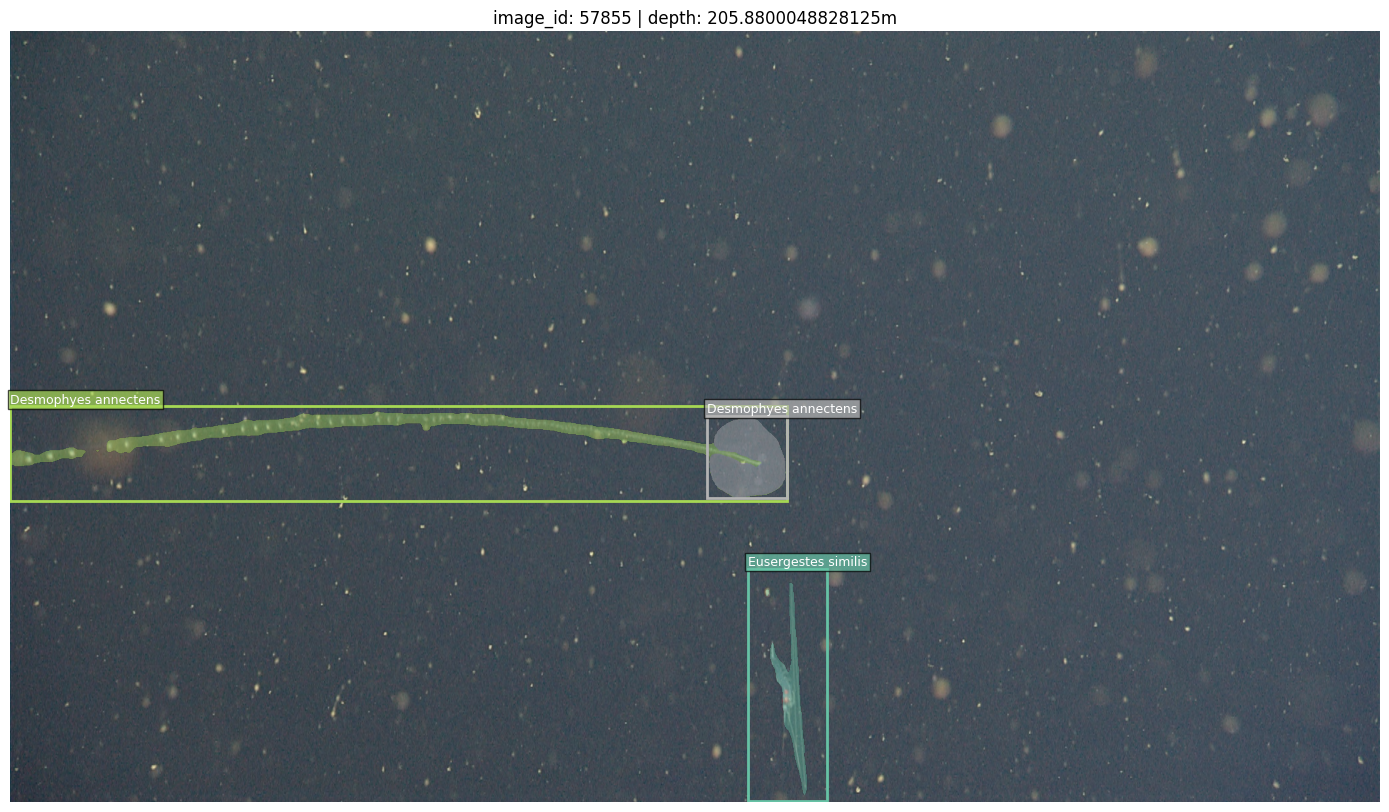

In [ ]:
# Load FathomNet metadata
df, coco = data.load_fathomnet_metadata(config.TRAIN_PATH, config.DEPTH_PATH)
#df_test, coco_test = data.load_fathomnet_metadata(config.TEST_PATH, config.DEPTH_PATH)

# Merged train and test so depth splits can be created later
# df: image_id, ann_id, species, bbox, depth_m, width, height
# coco: pycocotools COCO object (for mask retrieval later)
# df, coco = data.load_merged_metadata(df_train, df_test, coco_train, coco_test)

# Test
print(f'Total images: {len(df)}')
print(f'Depth range: {df["depth_m"].min():.0f}m – {df["depth_m"].max():.0f}m')

try:
    data.show_sample(coco, df, idx=65909)
except Exception as e:
    print(f"Warning: Failed to show sample image due to server error (skipping): {e}")

In [ ]:
import pandas as pd
data.summarise_depth_distribution(df)

def threshold_sweep(df, thresholds, min_n=5):
    rows = []
    for t in thresholds:
        counts = df.dropna(subset=['depth_m']).groupby('species')['depth_m'].apply(
            lambda d: pd.Series({
                'n_shallow': (d <= t).sum(),
                'n_deep': (d > t).sum(),
            })
        ).unstack()
        n_qualifying = ((counts['n_shallow'] >= min_n) & (counts['n_deep'] >= min_n)).sum()
        rows.append({'threshold': t, 'n_qualifying_species': n_qualifying})
    return pd.DataFrame(rows)

thresholds = [269, 427, 597, 837, 896, 1056, 1236, 1657, 3040]
threshold_sweep(df, thresholds, min_n=5)

counts_1056 = df.dropna(subset=['depth_m']).groupby('species')['depth_m'].apply(
    lambda d: pd.Series({'n_shallow': (d <= 1055.9).sum(), 'n_deep': (d > 1055.9).sum()})
).unstack()
qualifying_1056 = counts_1056[(counts_1056['n_shallow'] >= 5) & (counts_1056['n_deep'] >= 5)]
qualifying_1056['n_deep'].describe()



count    208286.000000
mean       1189.382294
std         962.826550
min           0.000000
25%         539.706482
50%         895.799988
75%        1309.929962
max        5954.757000
Name: depth_m, dtype: float64

 percentile  depth_m  n_shallow  n_deep
         10    269.0      20835  187451
         20    427.0      41658  166628
         30    597.5      62516  145770
         40    837.5      83337  124949
         50    895.8     104146  104140
         60   1055.9     124975   83311
         70   1236.0     145803   62483
         80   1657.1     166629   41657
         90   3040.1     187461   20825


,n_deep
count,314.000000
mean,214.238854
std,636.971175
min,5.000000
25%,12.000000
50%,37.500000
75%,130.750000
max,7927.000000


In [ ]:
# Split into shallow / deep
threshold = config.DEPTH_SHALLOW_MAX
shallow_df, deep_df = data.split_shallow_deep(df, threshold)

# Keep species with enough annotations on BOTH sides of the split
shallow_df, deep_df = data.restrict_to_common_species(shallow_df, deep_df, min_n=5)
all_df = pd.concat([shallow_df, deep_df], ignore_index=True)
species_list = sorted(shallow_df['species'].unique())
print(f'Shallow: {len(shallow_df)} | Deep: {len(deep_df)} | Species: {len(species_list)}')

Dropping 71832 rows with missing depth_m (25.6% of data)
Threshold 1056m -> shallow: 124982 (60.0%), deep: 83304 (40.0%)
Species with >= 5 annotations in BOTH splits: 314
Kept -> shallow: 105862 annotations | deep: 67250 annotations
Shallow: 105862 | Deep: 67250 | Species: 314


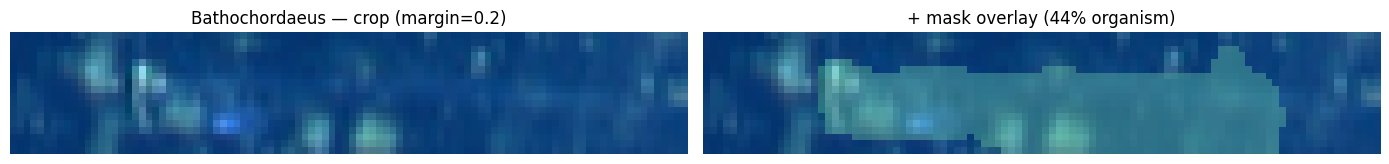

idx=20 skipped: Could not download image 183145


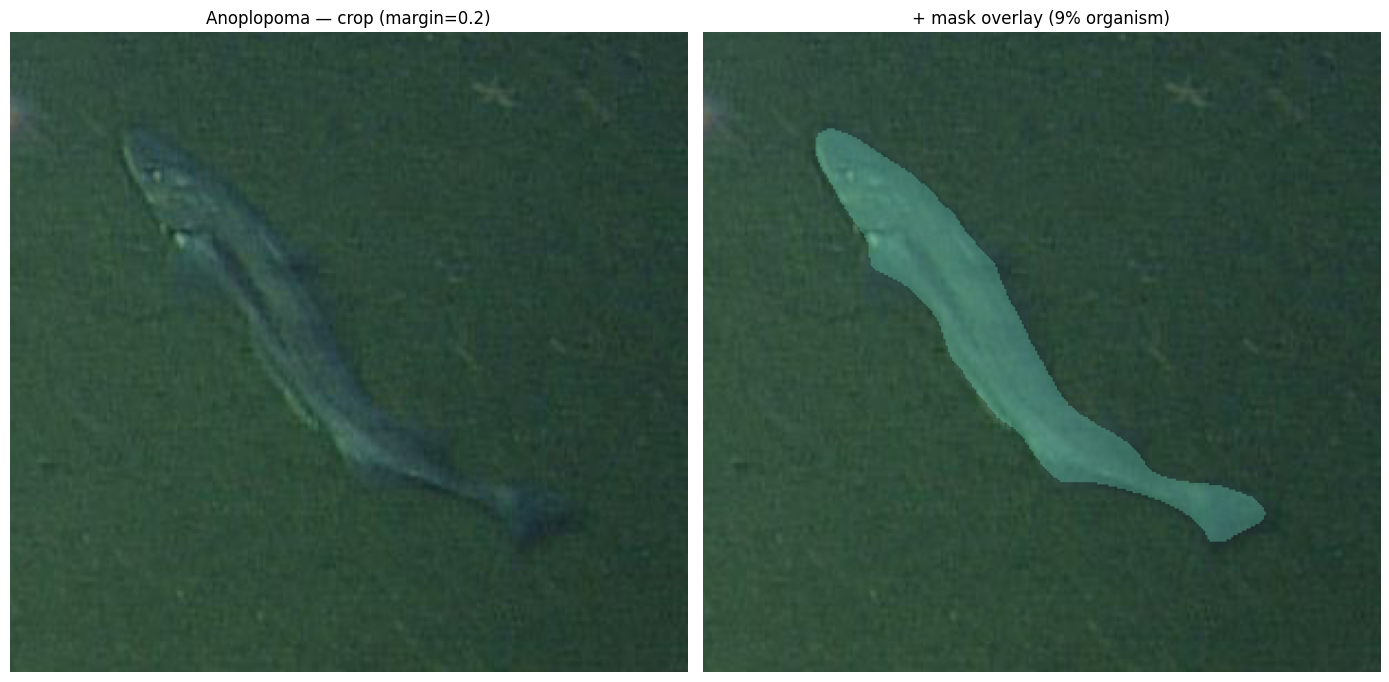

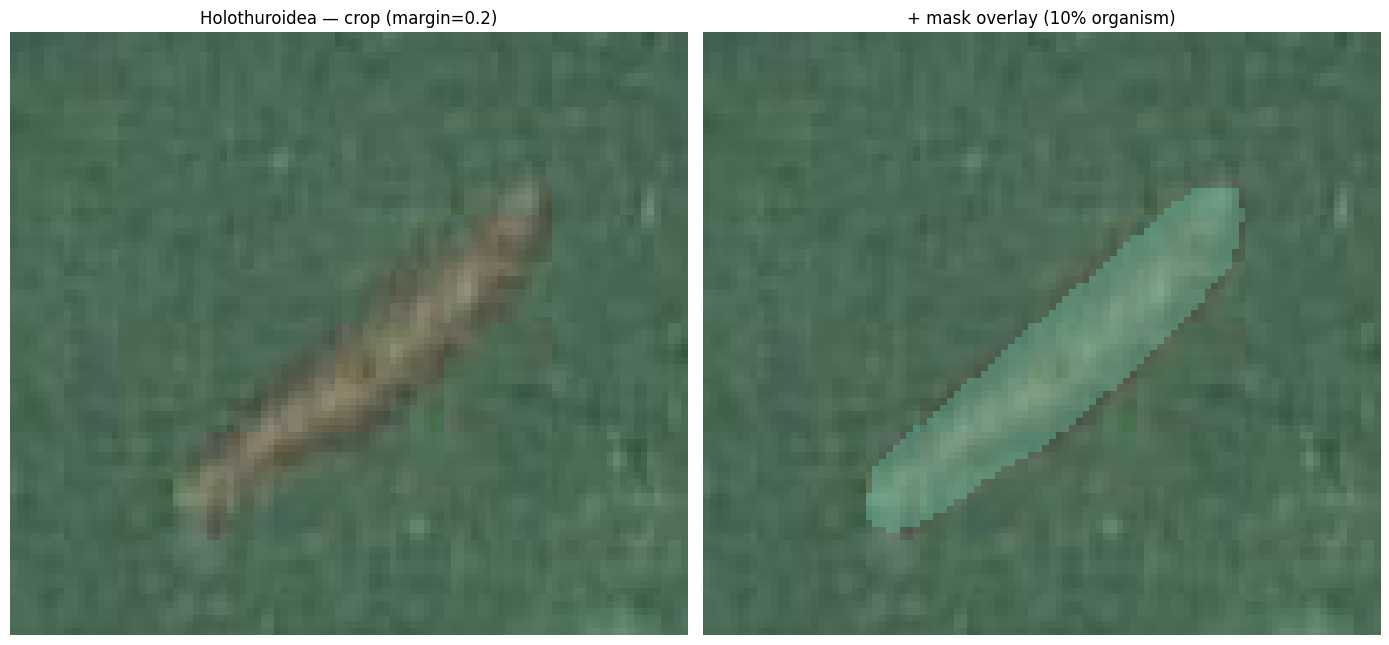

In [ ]:
# Crop a few annotations and check that crop_to_bounding_box keeps image and mask aligned
# check a handful, ideally different species and image sizes
for i in [0, 20, 25, 30]:
    row = df.iloc[i]
    try:
        img = data.get_image(coco, row['image_id'])
        full_mask = coco.annToMask(coco.loadAnns([int(row['ann_id'])])[0])
        crop, crop_mask, _ = data.crop_to_bounding_box(img, row['bbox'], mask=full_mask)
    except (RuntimeError, ValueError) as e:   # download failed / degenerate bbox
        print(f"idx={i} skipped: {e}")
        continue
    data.display_image(crop, masks=crop_mask, show_original=True,
                       title=f"{row['species']} — crop (margin={config.CROP_MARGIN})")

In [ ]:
# Crops: restore from the shared archive, or download once and create it
if os.path.exists(config.CROP_ARCHIVE):
    if not os.path.isdir(config.CROP_DIR):
        data.restore_dir(config.CROP_ARCHIVE, config.CROP_DIR)
n_saved, _ = data.prepare_crops(all_df)
if n_saved or not os.path.exists(config.CROP_ARCHIVE):
    data.archive_dir(config.CROP_DIR, config.CROP_ARCHIVE)   # only rewrite the shared archive when there are new crops

# Crops that could not be downloaded are dropped so the loaders all agree
shallow_df = data.drop_missing_crops(shallow_df)
deep_df = data.drop_missing_crops(deep_df)
all_df = pd.concat([shallow_df, deep_df], ignore_index=True)

# Build DataLoaders
train_loader = data.get_dataloaders(shallow_df, split='train', species_list=species_list)
val_loader   = data.get_dataloaders(shallow_df, split='val', species_list=species_list)
shallow_test_loader = data.get_dataloaders(shallow_df, split='test', species_list=species_list)
deep_test_loader    = data.get_dataloaders(deep_df, split='test', species_list=species_list)



Restored 173080 files to /content/crops/
32 crops missing across 24 images to fetch
Done: saved 0 crops, 32 failed/skipped
Dropping 17 rows with no crop on disk
Dropping 15 rows with no crop on disk
train: 73711 crops, 314 classes
val: 10811 crops, 314 classes
test: 21323 crops, 314 classes
test: 12926 crops, 314 classes


## 2 · Control (trained on all depths)
Builds control classifier trained on all depths.
Holds architecture and training procedure fixed and varies only the training distribution,
so degradation differences can be attributed to distribution shift rather than model capacity.

In [ ]:
import time
import numpy as np
import pandas as pd
import os

SKIP_CONTROL = False  # True = classifier only

control_results = None
if not SKIP_CONTROL:
    print("\n--- Training control model (all depths) ---")
    control_ckpt_path = config.MODEL_SAVE_PATH + "control_resnet50.pt"

    # Seed before creating the control model
    model.set_seed(config.RANDOM_SEED)

    control = model.build_classifier(num_classes=len(species_list), pretrained=config.PRETRAINED)

    all_loader = data.get_dataloaders(all_df, split="train", species_list=species_list)
    all_val_loader = data.get_dataloaders(all_df, split="val", species_list=species_list)

    if os.path.exists(control_ckpt_path):
        print(f"Found existing checkpoint at {control_ckpt_path} - loading instead of retraining")
        control = model.load_checkpoint(control, control_ckpt_path)
        # Note: If loading from a saved checkpoint, control_history won't be defined here.
        # Let's initialize a placeholder or define it to avoid NameError on reload
        control_history = {"val_acc": []}
    else:
        t0 = time.time()
        control, control_history = model.train(control, all_loader, all_val_loader,
                                               epochs=config.EPOCHS, lr=config.LEARNING_RATE,
                                               resume_path=control_ckpt_path + ".resume")
        model.save_checkpoint(control, control_ckpt_path)
        print(f"Control training took {(time.time() - t0) / 60:.1f} min, saved to {control_ckpt_path}")

    control_results = evaluation.evaluate_control_model(
        control, shallow_test_loader, deep_test_loader, species_list
    )
    print(f"Control mean shallow accuracy: {pd.Series(control_results['shallow_acc']).mean():.3f}")
    print(f"Control mean deep accuracy:    {pd.Series(control_results['deep_acc']).mean():.3f}")

if 'control_history' in locals() and "val_acc" in control_history:
    np.save("control_history_run2.npy", # used to verify seeding results
            np.array(control_history["val_acc"]))



--- Training control model (all depths) ---
Random seed set to 42
Downloading: "https://download.pytorch.org/models/resnet50-11ad3fa6.pth" to /root/.cache/torch/hub/checkpoints/resnet50-11ad3fa6.pth


100%|██████████| 97.8M/97.8M [00:00<00:00, 170MB/s]


train: 121132 crops, 314 classes
val: 17699 crops, 314 classes
Epoch 1/12 | train_loss=1.2247 train_acc=0.7008 | val_loss=0.7788 val_acc=0.7802
Epoch 2/12 | train_loss=0.5721 train_acc=0.8282 | val_loss=0.6880 val_acc=0.8037
Epoch 3/12 | train_loss=0.4290 train_acc=0.8655 | val_loss=0.6351 val_acc=0.8189
Epoch 4/12 | train_loss=0.3417 train_acc=0.8895 | val_loss=0.6365 val_acc=0.8215
Epoch 5/12 | train_loss=0.2755 train_acc=0.9093 | val_loss=0.6538 val_acc=0.8218
Epoch 6/12 | train_loss=0.2268 train_acc=0.9233 | val_loss=0.6740 val_acc=0.8228
Epoch 7/12 | train_loss=0.1845 train_acc=0.9380 | val_loss=0.6919 val_acc=0.8242
Epoch 8/12 | train_loss=0.1524 train_acc=0.9487 | val_loss=0.7412 val_acc=0.8218
Epoch 9/12 | train_loss=0.1294 train_acc=0.9569 | val_loss=0.7339 val_acc=0.8260
Epoch 10/12 | train_loss=0.1104 train_acc=0.9628 | val_loss=0.8005 val_acc=0.8149
Epoch 11/12 | train_loss=0.0953 train_acc=0.9682 | val_loss=0.7905 val_acc=0.8218
Epoch 12/12 | train_loss=0.0831 train_acc=0.

## 3 · Train classifier (shallow-depth only)

In [ ]:
print("\n--- Training classifier (shallow only) ---")

# Seed before creating the shallow classifier
model.set_seed(config.RANDOM_SEED)

classifier = model.build_classifier(num_classes=len(species_list))

ckpt_path = config.MODEL_SAVE_PATH + "shallow_resnet50.pt"
if os.path.exists(ckpt_path):
    print(f"Found existing checkpoint at {ckpt_path} - loading instead of retraining")
    classifier = model.load_checkpoint(classifier, ckpt_path)
    # Initialize placeholder to avoid NameError on reload
    shallow_history = {"val_acc": []}
else:
    t0 = time.time()
    classifier, shallow_history = model.train(classifier, train_loader, val_loader,
                                      epochs=config.EPOCHS, lr=config.LEARNING_RATE,
                                      resume_path=ckpt_path + ".resume")
    model.save_checkpoint(classifier, ckpt_path)
    print(f"Training took {(time.time() - t0) / 60:.1f} min, saved to {ckpt_path}")

if 'shallow_history' in locals() and "val_acc" in shallow_history:
    np.save("shallow_history_run2.npy", # used to verify seeding results
            np.array(shallow_history["val_acc"]))



--- Training classifier (shallow only) ---
Random seed set to 42
Epoch 1/12 | train_loss=1.3409 train_acc=0.6888 | val_loss=0.7434 val_acc=0.7959
Epoch 2/12 | train_loss=0.5645 train_acc=0.8339 | val_loss=0.6416 val_acc=0.8196
Epoch 3/12 | train_loss=0.4085 train_acc=0.8720 | val_loss=0.6309 val_acc=0.8244
Epoch 4/12 | train_loss=0.3112 train_acc=0.8988 | val_loss=0.6189 val_acc=0.8328
Epoch 5/12 | train_loss=0.2447 train_acc=0.9190 | val_loss=0.6369 val_acc=0.8305
Epoch 6/12 | train_loss=0.1955 train_acc=0.9349 | val_loss=0.6559 val_acc=0.8304
Epoch 7/12 | train_loss=0.1543 train_acc=0.9483 | val_loss=0.6672 val_acc=0.8331
Epoch 8/12 | train_loss=0.1331 train_acc=0.9556 | val_loss=0.7094 val_acc=0.8317
Epoch 9/12 | train_loss=0.1064 train_acc=0.9649 | val_loss=0.7239 val_acc=0.8342
Epoch 10/12 | train_loss=0.0987 train_acc=0.9670 | val_loss=0.7745 val_acc=0.8292
Epoch 11/12 | train_loss=0.0817 train_acc=0.9738 | val_loss=0.7561 val_acc=0.8364
Epoch 12/12 | train_loss=0.0758 train_acc

## 4 · Evaluation

In [ ]:
import os
import pandas as pd

predictions_path = "results/predictions.csv"
REUSE_PREDICTIONS = False   # the old cache is corrupted; set True only after one clean run

if REUSE_PREDICTIONS and os.path.exists(predictions_path):
    p = pd.read_csv(predictions_path)
    main = p[p["model"] == "shallow"]
    shallow_preds = main[main["split"] == "shallow"].drop(columns=["model", "split"])
    deep_preds    = main[main["split"] == "deep"].drop(columns=["model", "split"])
else:
    shallow_preds = evaluation.predict(classifier, shallow_test_loader)
    deep_preds    = evaluation.predict(classifier, deep_test_loader)

shallow_acc = evaluation.accuracy_from_predictions(shallow_preds, species_list)
deep_acc    = evaluation.accuracy_from_predictions(deep_preds, species_list)
degradation = evaluation.compute_degradation(shallow_acc, deep_acc)

print(f"Shallow preds: {len(shallow_preds)} | Deep preds: {len(deep_preds)}")  # expect 21323 | 12926
print(f"Mean shallow accuracy: {pd.Series(shallow_acc).mean():.3f}")
print(f"Mean deep accuracy:    {pd.Series(deep_acc).mean():.3f}")
majority_acc = evaluation.majority_class_baseline(shallow_test_loader)
print(f"Majority-class baseline: {majority_acc:.3f}")

Shallow preds: 21323 | Deep preds: 12926
Mean shallow accuracy: 0.513
Mean deep accuracy:    0.307
Majority-class baseline: 0.179


### Save results

In [ ]:
# Per-species accuracy -> results/per_species_accuracy.csv
# Per-image predictions -> results/predictions.csv
per_species_df, predictions_df = evaluation.save_results(
    species_list, shallow_preds, deep_preds, control_results)
per_species_df.head()

Saved 314 species to results/per_species_accuracy.csv
Saved 68498 predictions to results/predictions.csv


,n_shallow_test,n_deep_test,shallow_acc,deep_acc,degradation,control_shallow_acc,control_deep_acc,control_degradation
species,,,,,,,,
Acanthascinae,70,10,0.500000,0.000000,0.500000,0.114286,0.100000,0.014286
Acanthephyra,0,10,NaN,0.500000,NaN,NaN,0.600000,NaN
Acanthogorgia,4,3,0.250000,0.333333,-0.083333,0.500000,0.666667,-0.166667
Acesta,11,1,1.000000,0.000000,1.000000,0.909091,0.000000,0.909091
Actiniaria,444,432,0.725225,0.648148,0.077077,0.743243,0.745370,-0.002127


## 5 · Attribution & Context Reliance Score

### Crop Masks

test: 21323 crops, 314 classes
Restored 34249 files to /content/masks/
Masks: 0 newly saved, 21323 already cached in /content/masks/


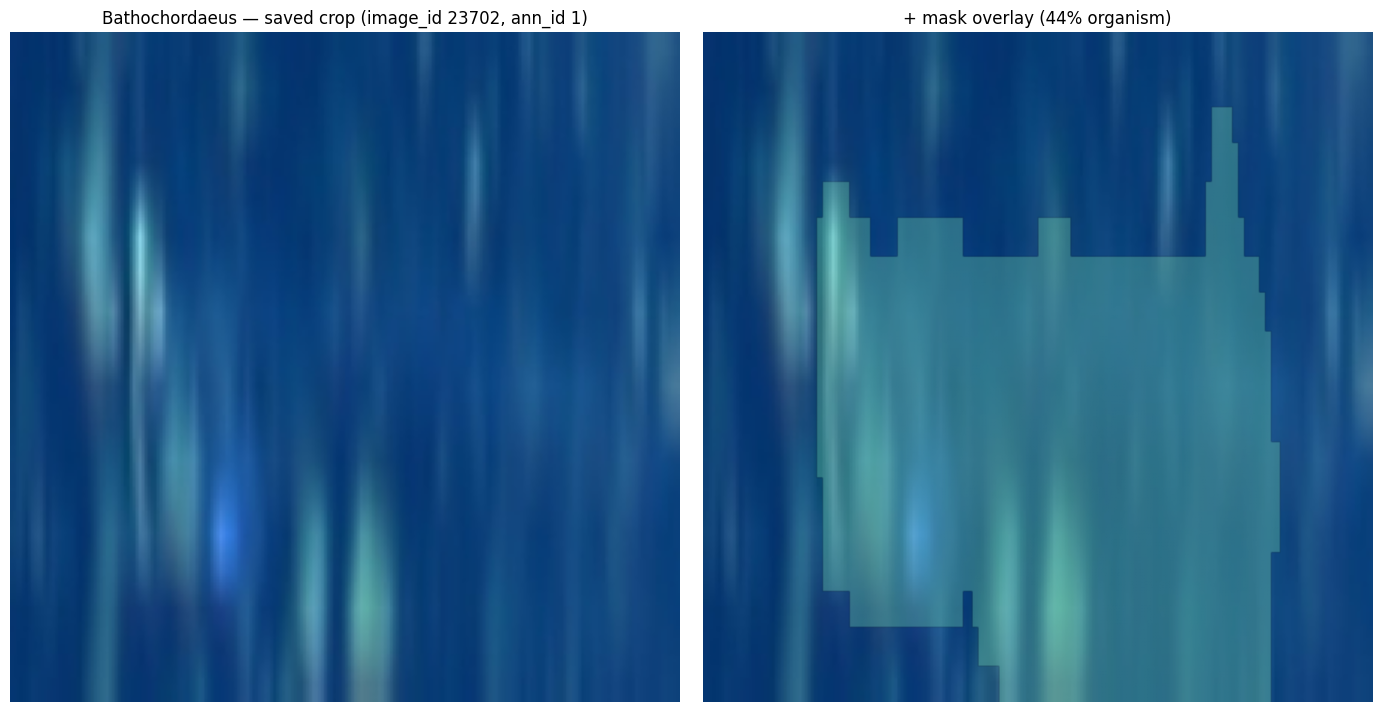

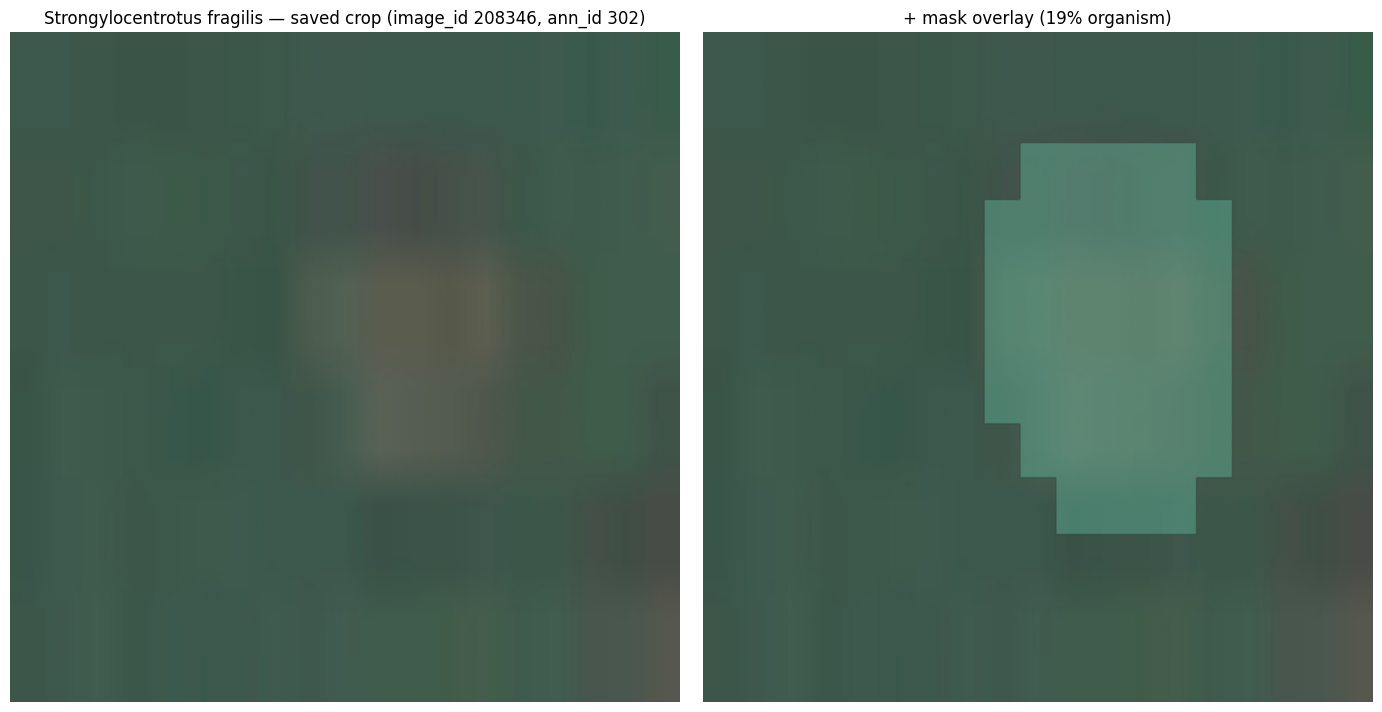

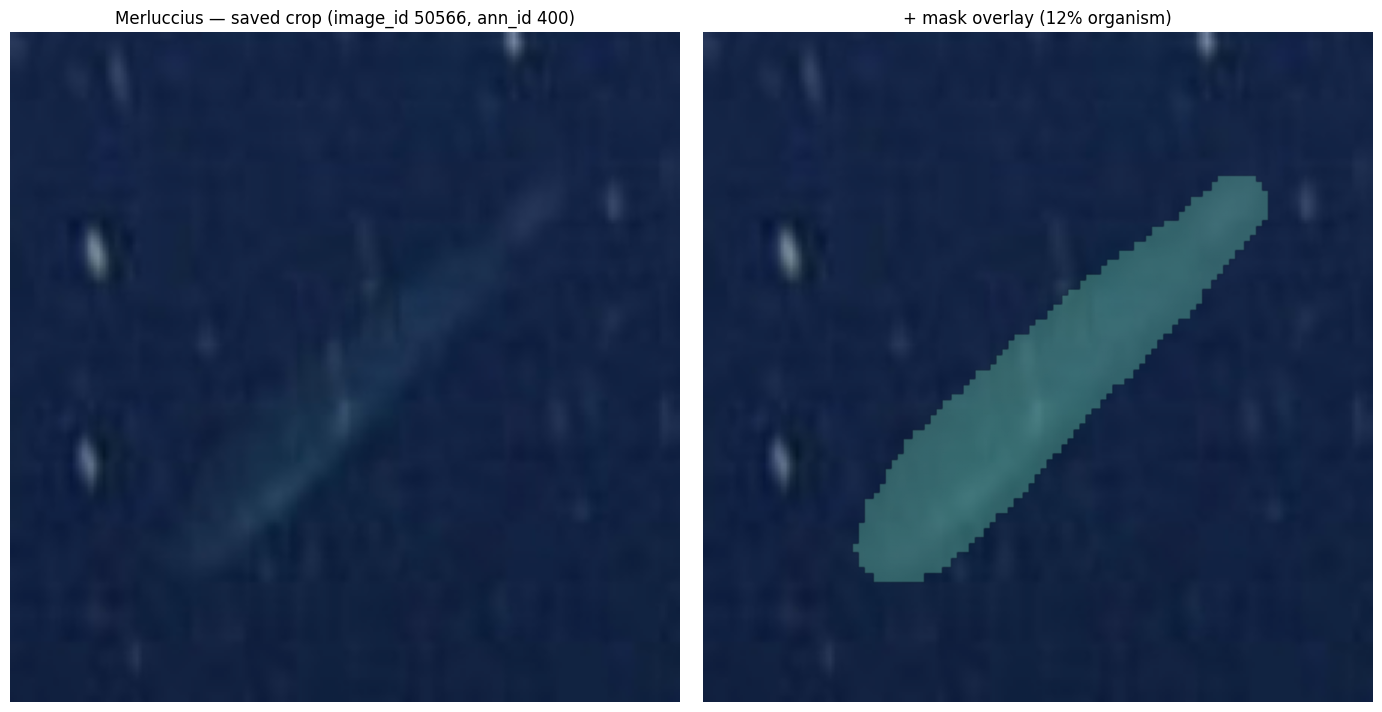

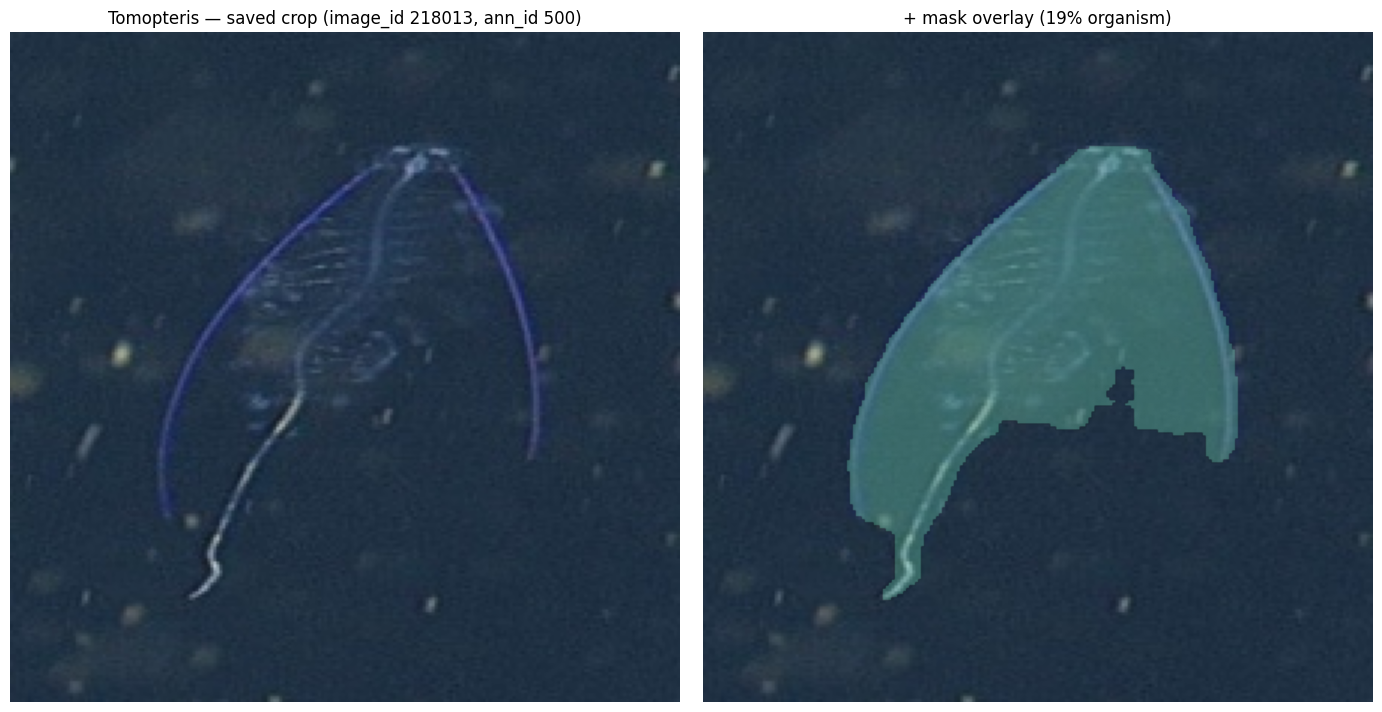

In [ ]:
# Save crop masks

# Same crops as shallow_test_loader, plus crop-aligned masks (for CRS in section 5)
shallow_test_mask_loader = data.get_dataloaders(shallow_df, split='test', species_list=species_list,
                                               coco=coco)
# Masks: restore from the shared archive, compute any missing, re-archive only if new ones were made
if os.path.exists(config.MASK_ARCHIVE) and not os.path.isdir(config.MASK_DIR):
    data.restore_dir(config.MASK_ARCHIVE, config.MASK_DIR)
n_new_masks = data.prepare_masks(shallow_test_mask_loader)
if n_new_masks or not os.path.exists(config.MASK_ARCHIVE):
    data.archive_dir(config.MASK_DIR, config.MASK_ARCHIVE)

# show_saved_crops: loads the saved 224x224 crops + get_crop_mask masks - tests what Grad-CAM/CRS actually receive is aligned
data.show_saved_crops(shallow_test_mask_loader, idxs=[0, 20, 25, 30])

### Grad-CAM Heatmaps

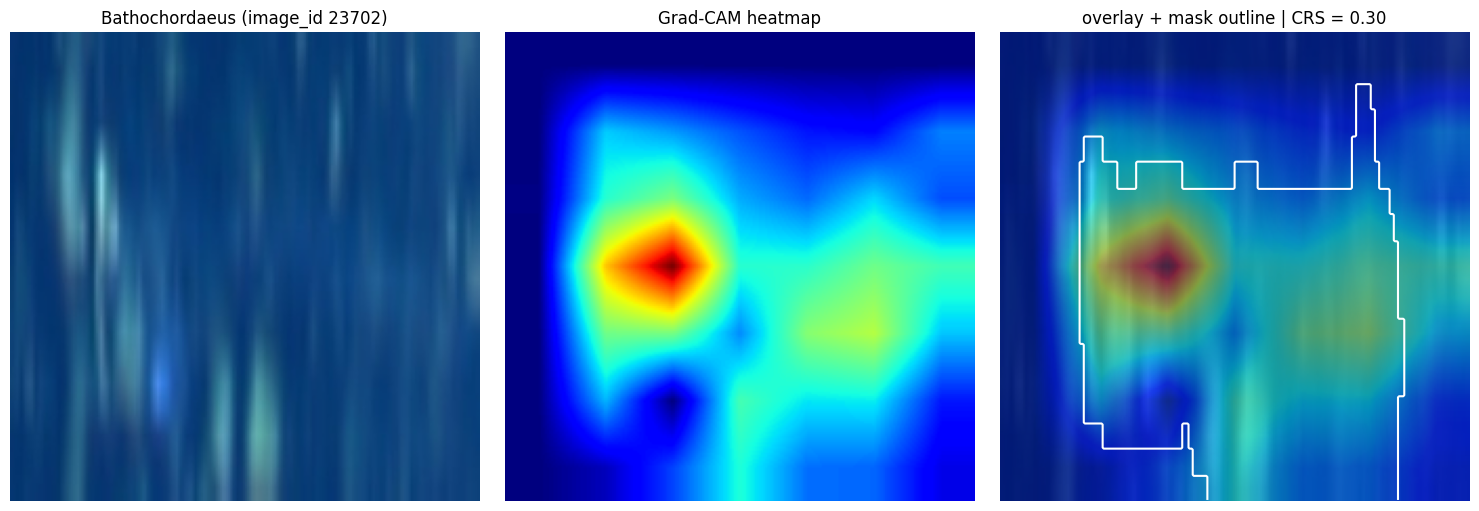

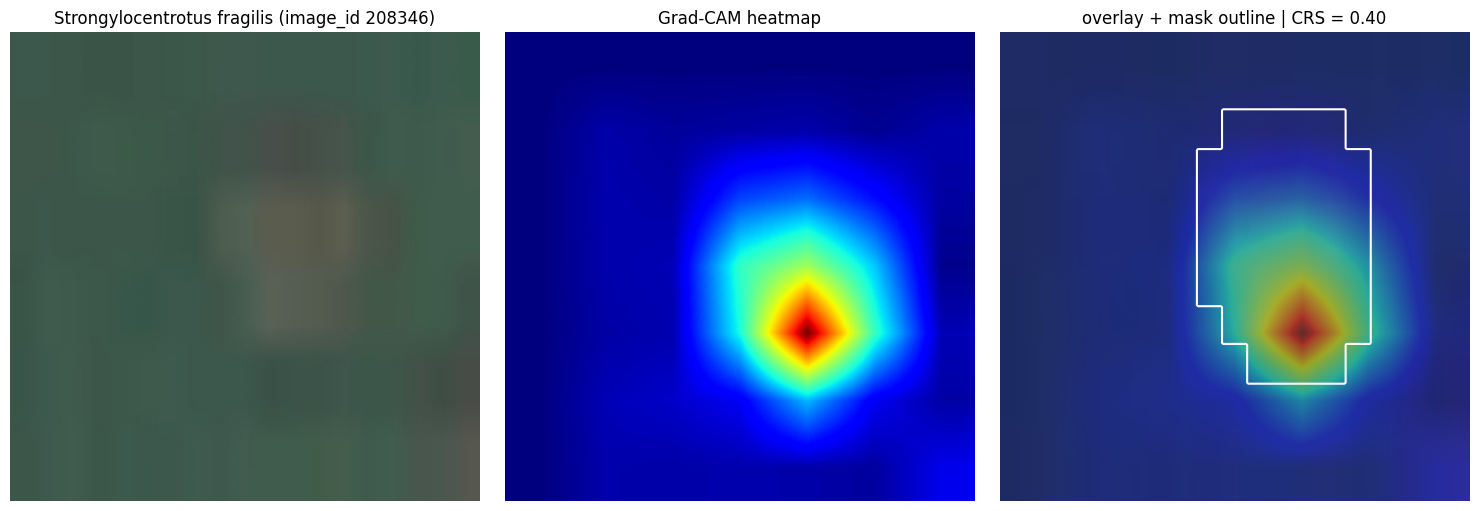

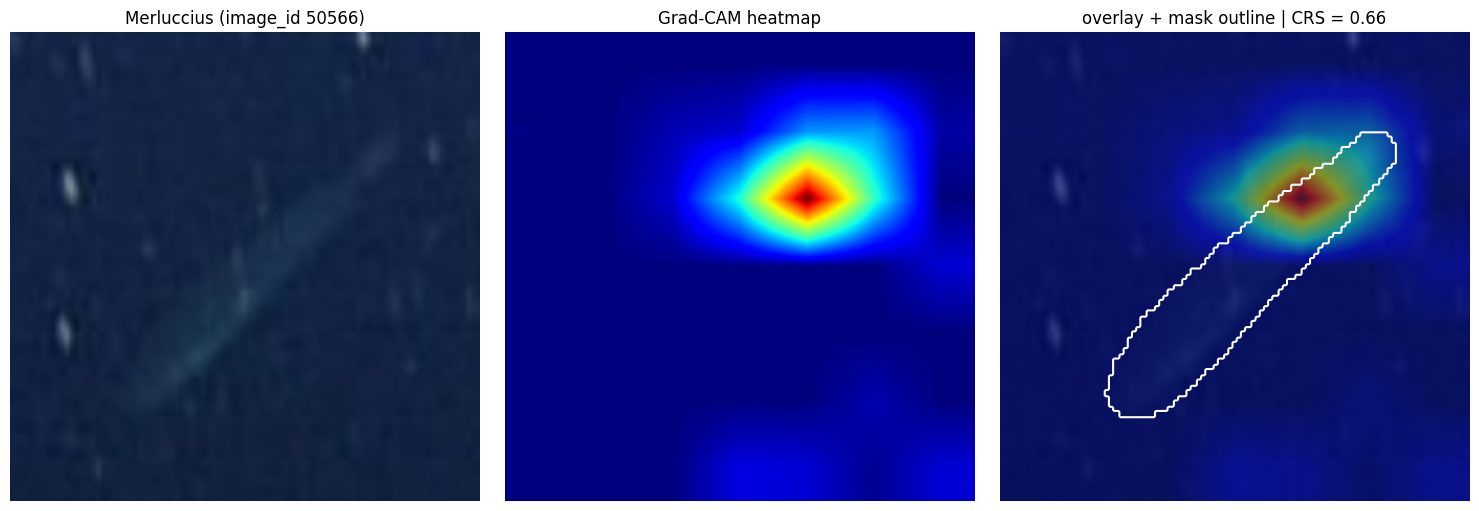

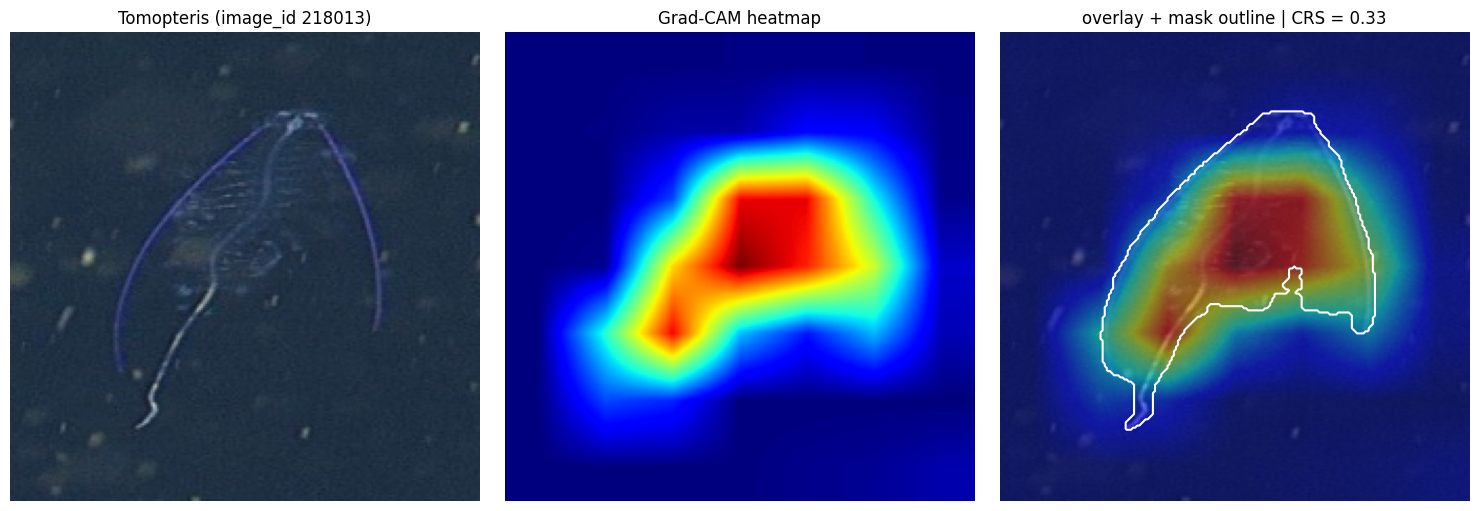

In [ ]:
# Grad-CAM heatmaps on a few shallow test crops (explained for the true species)
# Mask outline in white; CRS = fraction of the heatmap outside the organism
import matplotlib.pyplot as plt

ds = shallow_test_mask_loader.dataset
mean = torch.tensor(data.IMAGENET_MEAN).view(3, 1, 1)
std = torch.tensor(data.IMAGENET_STD).view(3, 1, 1)

for i in [0, 20, 25, 30]:
    img, label, mask = ds[i]
    heatmap = attribution.compute_gradcam(classifier, img, label)
    crs = attribution.compute_crs(heatmap, mask)
    rgb = (img * std + mean).clamp(0, 1).permute(1, 2, 0).numpy()  # undo Normalize

    fig, axes = plt.subplots(1, 3, figsize=(15, 5))
    axes[0].imshow(rgb)
    axes[0].set_title(f"{species_list[label]} (image_id {ds.image_ids[i]})")
    axes[1].imshow(heatmap, cmap='jet', vmin=0, vmax=1)
    axes[1].set_title("Grad-CAM heatmap")
    axes[2].imshow(rgb)
    axes[2].imshow(heatmap, cmap='jet', alpha=0.5, vmin=0, vmax=1)
    axes[2].contour(mask.numpy(), levels=[0.5], colors='white', linewidths=1.5)
    axes[2].set_title(f"overlay + mask outline | CRS = {crs:.2f}")
    for ax in axes:
        ax.axis('off')
    plt.tight_layout()
    plt.show()

In [ ]:
# Baseline attribution maps (also save to results.csv)
uniform_crs  = attribution.compute_species_baseline_crs(shallow_test_mask_loader, species_list, 'uniform')
gaussian_crs = attribution.compute_species_baseline_crs(shallow_test_mask_loader, species_list, 'gaussian')
per_species_df['uniform_crs']  = pd.Series(uniform_crs)
per_species_df['gaussian_crs'] = pd.Series(gaussian_crs)
per_species_df.to_csv(os.path.join(config.RESULTS_DIR, 'results.csv'))

uniform baseline CRS: scored 21323 / 21323 images
gaussian baseline CRS: scored 21323 / 21323 images


### Context-Reliance Score

In [ ]:
# Compute per-species CRS on shallow test set
crs_scores = attribution.compute_species_crs(classifier, shallow_test_mask_loader, species_list)
print('CRS per species:', crs_scores)

per_species_df['crs'] = pd.Series(crs_scores)
per_species_df.to_csv(os.path.join(config.RESULTS_DIR, 'results.csv'))

#TODO maybe print some attribution maps of species with high scores

CRS: scored 21273 / 21323 images (50 had an empty Grad-CAM map)
CRS per species: {'Acanthascinae': 0.29260098737265383, 'Acanthephyra': nan, 'Acanthogorgia': 0.4941251203417778, 'Acesta': 0.5986016365614805, 'Actiniaria': 0.43249347656629644, 'Actiniidae': 0.2971911313278334, 'Actinopterygii': 0.8709059305050794, 'Actinostolidae': 0.3117585312575102, 'Actinostoloidea': 0.2844256521513065, 'Aegina': 0.6530598979803823, 'Aegina citrea': 0.5548531650565565, 'Aegina rosea': 0.9972681403160095, 'Akoya platinum': 0.3492156224591391, 'Alcyonacea': 0.8714516162872314, 'Amphipoda': 0.5608662389218807, 'Anoplogaster cornuta': 0.4669484333558516, 'Anoplopoma': 0.5258821010589599, 'Antedonoidea': 0.3277021236717701, 'Anthomastus': 0.5727521330118179, 'Anthozoa': 0.9611468464136124, 'Antimora microlepis': 0.6237932920455933, 'Antipatharia': 0.6687254123389721, 'Apolemia': 0.5861019670431104, 'Apolemia lanosa': 0.627150371670723, 'Asbestopluma': 0.7266138152281443, 'Asbestopluma monticola': 0.476077

In [ ]:
qualifying = analysis.select_qualifying_species(per_species_df, min_test_n=5)

139 / 314 species qualify (>= 5 shallow and deep test crops, CRS available)


test: 12926 crops, 314 classes
Masks: 0 newly saved, 12926 already cached in /content/masks/


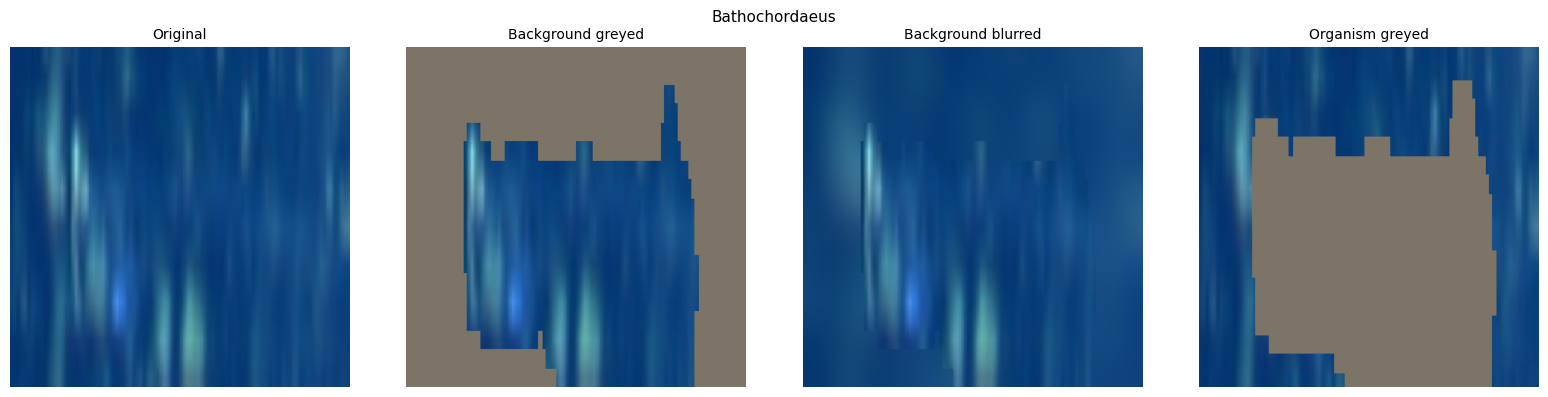

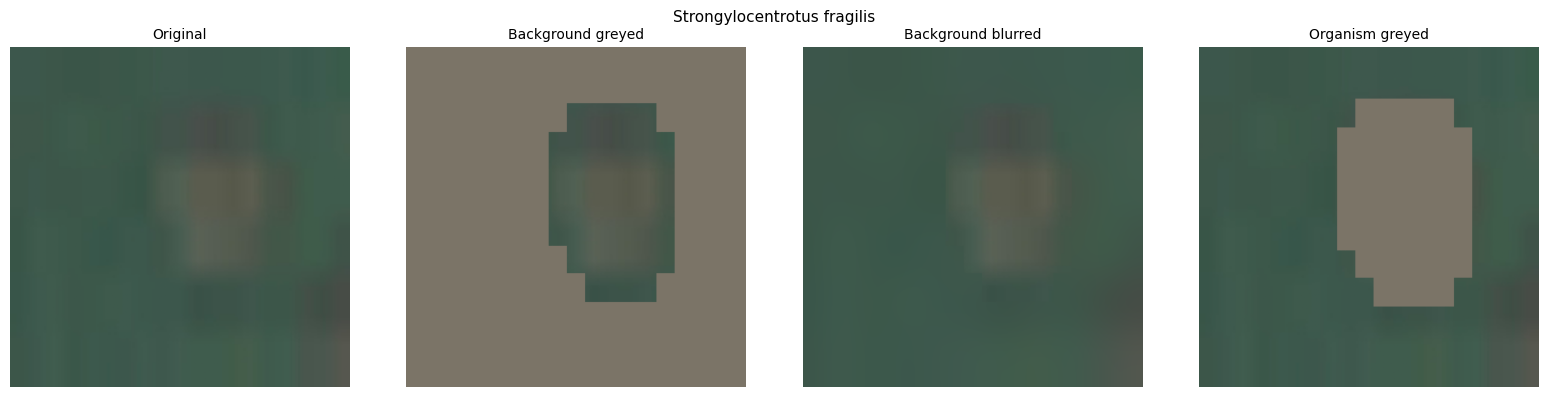

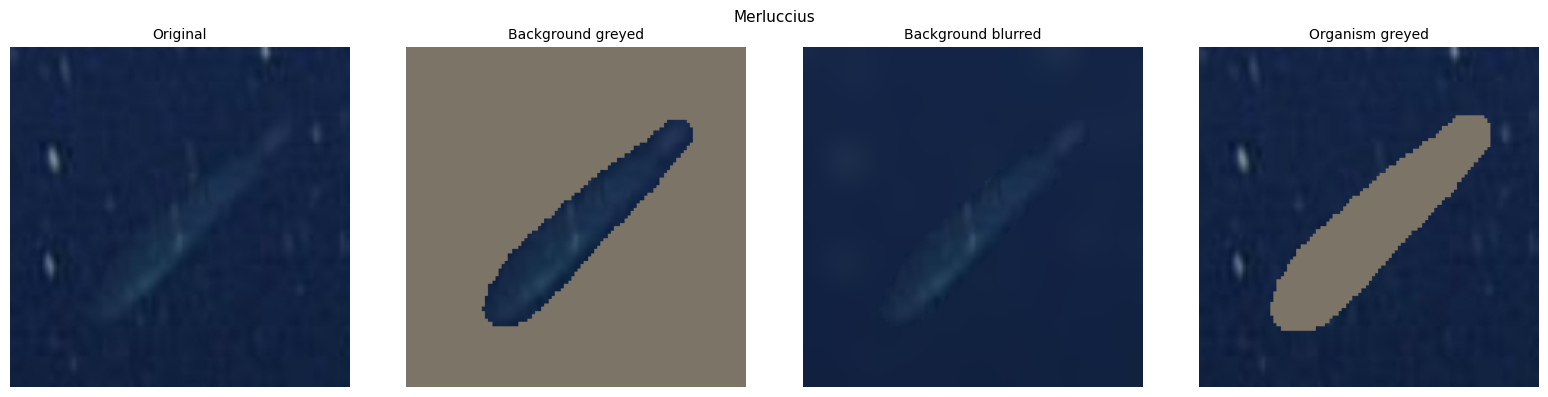

In [ ]:
import importlib, extensions
importlib.reload(extensions)

deep_test_mask_loader = data.get_dataloaders(deep_df, split='test', species_list=species_list, coco=coco)
n_new = data.prepare_masks(deep_test_mask_loader)
if n_new:
    data.archive_dir(config.MASK_DIR, config.MASK_ARCHIVE)   # adds the deep masks to the shared masks.tar
mask_loaders = {'shallow': shallow_test_mask_loader, 'deep': deep_test_mask_loader}

extensions.show_interventions(shallow_test_mask_loader, idxs=[0, 20, 25])   # look at the edited crops

## Background Intervention

shallow_acc  deep_acc  degradation  n_species
model   mode                                                             
shallow Original                  0.592     0.440        0.151        139
        Background greyed         0.240     0.201        0.038        139
        Background blurred        0.433     0.337        0.096        139
        Organism greyed           0.066     0.036        0.029        139
control Original                  0.618     0.670       -0.052        139
        Background greyed         0.269     0.304       -0.036        139
        Background blurred        0.500     0.532       -0.033        139
        Organism greyed           0.054     0.048        0.006        139

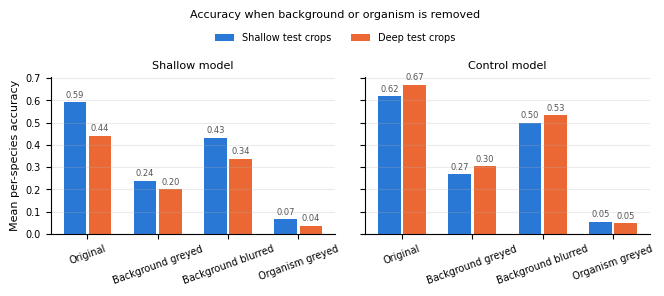

CRS vs accuracy drop (Background greyed): rho = -0.050, p = 0.556, n = 139 species
CRS vs accuracy drop (Background blurred): rho = -0.117, p = 0.17, n = 139 species


In [ ]:
int_path = os.path.join(config.RESULTS_DIR, 'intervention_predictions.csv')
if os.path.exists(int_path):
    int_preds = pd.read_csv(int_path)
else:
    int_preds = extensions.run_interventions({'shallow': classifier, 'control': control},
                                             mask_loaders, species_list)
    int_preds.to_csv(int_path, index=False)

int_summary = extensions.intervention_summary(int_preds, species=qualifying)
int_summary.to_csv(os.path.join(config.RESULTS_DIR, 'intervention_summary.csv'))
display(int_summary.round(3))
extensions.plot_intervention_summary(int_summary, save_path='results/intervention_accuracy.png')

# Does greying the background hurt the species Grad-CAM said rely on it?
bg_dep, bg_dep_stats = extensions.background_dependence(int_preds, crs_scores, species=qualifying)

In [ ]:
cs_shallow = extensions.colour_stats(shallow_test_mask_loader)
cs_deep = extensions.colour_stats(deep_test_mask_loader)
shift = extensions.species_shift(cs_shallow, cs_deep)
per_species_df = per_species_df.drop(columns=shift.columns, errors='ignore').join(shift)
per_species_df.to_csv(os.path.join(config.RESULTS_DIR, 'results.csv'))

spear, grid, fit = extensions.shift_analysis(per_species_df, species=qualifying)
display(spear.round(3))
display(grid.round(3))
print(fit.summary())

Shift analysis over 139 species


,spearman_rho,p_value
predictor,,
bg_colour_shift,0.060,0.480
org_colour_shift,0.180,0.034
crs,-0.193,0.023


mean                      count             
shift_group high bg shift low bg shift high bg shift low bg shift
crs_group                                                        
high CRS            0.140        0.132            33           36
low CRS             0.194        0.172            36           34

                            OLS Regression Results                            
Dep. Variable:            degradation   R-squared:                       0.084
Model:                            OLS   Adj. R-squared:                  0.057
Method:                 Least Squares   F-statistic:                     3.081
Date:                Mon, 26 Oct 2026   Prob (F-statistic):             0.0183
Time:                        10:33:57   Log-Likelihood:                 1.5763
No. Observations:                 139   AIC:                             6.847
Df Residuals:                     134   BIC:                             21.52
Df Model:                           4                                         
Covariance Type:            nonrobust                                         
                   coef    std err          t      P>|t|      [0.025      0.975]
--------------------------------------------------------------------------------
Intercept        0.1594      0.021      7.709   

## Background Swap

Background bank: 1000 donors from 21323 crops
Background bank: 1000 donors from 12926 crops


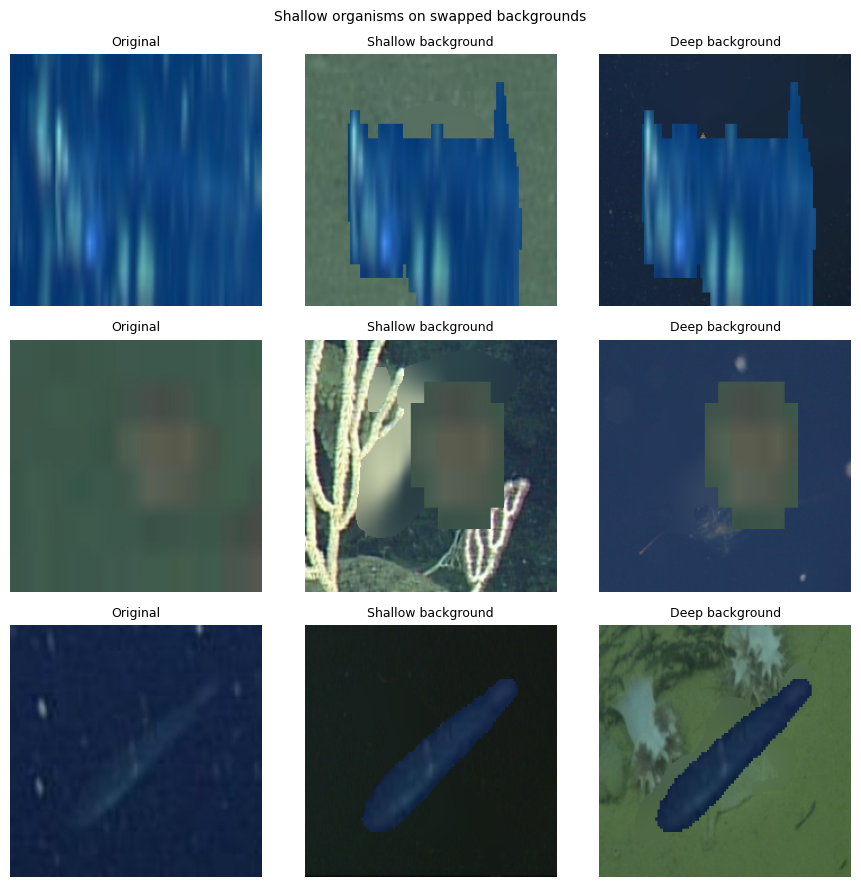

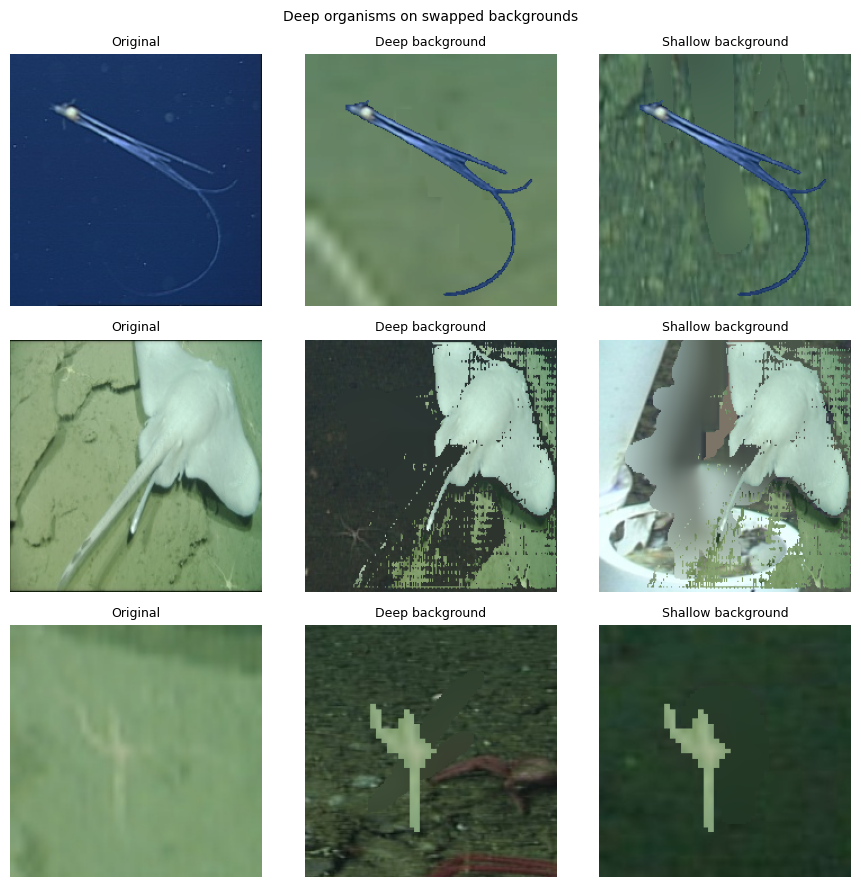

In [ ]:
# Background swap: paste each organism onto a same-depth and an other-depth background
importlib.reload(extensions)

banks = {s: extensions.build_background_bank(l) for s, l in mask_loaders.items()}

# Look at some composites before trusting the numbers
extensions.show_swaps(mask_loaders, banks, split='shallow', idxs=[0, 20, 25],
                      save_path='results/swap_examples_shallow.png')
extensions.show_swaps(mask_loaders, banks, split='deep', idxs=[0, 20, 25],
                      save_path='results/swap_examples_deep.png')

swap_path = os.path.join(config.RESULTS_DIR, 'swap_predictions.csv')
if os.path.exists(swap_path):
    swap_preds = pd.read_csv(swap_path)
else:
    swap_preds = extensions.run_background_swap({'shallow': classifier, 'control': control},
                                                mask_loaders, banks, species_list)
    swap_preds.to_csv(swap_path, index=False)

[shallow] median CRS correct 0.472 vs incorrect 0.538 (pooled p = 8.67e-40); within 97 species, median diff = 0.072 (p = 3.8e-11)
[deep] median CRS correct 0.523 vs incorrect 0.600 (pooled p = 1.95e-53); within 93 species, median diff = 0.078 (p = 1.31e-08)


,split,n_correct,n_incorrect,median_crs_correct,median_crs_incorrect,p_pooled,n_species_within,median_within_species_diff,p_within
0,shallow,10661,2864,0.4718,0.5378,0.0,97,0.0716,0.0
1,deep,6494,3881,0.5230,0.5995,0.0,93,0.0780,0.0


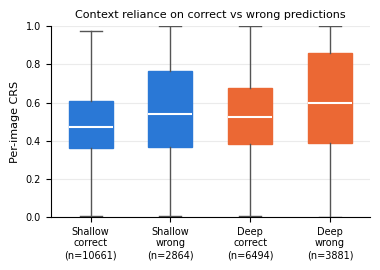

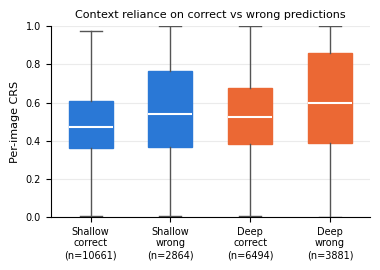

In [ ]:
img_crs_path = os.path.join(config.RESULTS_DIR, 'image_crs.csv')
if os.path.exists(img_crs_path):
    all_ic = pd.read_csv(img_crs_path)
    image_crs = {s: all_ic[all_ic['split'] == s].drop(columns='split') for s in ['shallow', 'deep']}
else:
    image_crs = {'shallow': extensions.compute_image_crs(classifier, shallow_test_mask_loader),
                 'deep': extensions.compute_image_crs(classifier, deep_test_mask_loader)}
    pd.concat([df.assign(split=s) for s, df in image_crs.items()]).to_csv(img_crs_path, index=False)

cw = pd.DataFrame([extensions.crs_correct_vs_incorrect(image_crs[s], species=qualifying, label=s)
                   for s in ['shallow', 'deep']])
cw.to_csv(os.path.join(config.RESULTS_DIR, 'crs_correct_vs_incorrect.csv'), index=False)
display(cw.round(4))
extensions.plot_crs_correct_vs_incorrect(image_crs, species=qualifying,
                                         save_path='results/crs_correct_vs_wrong.png')

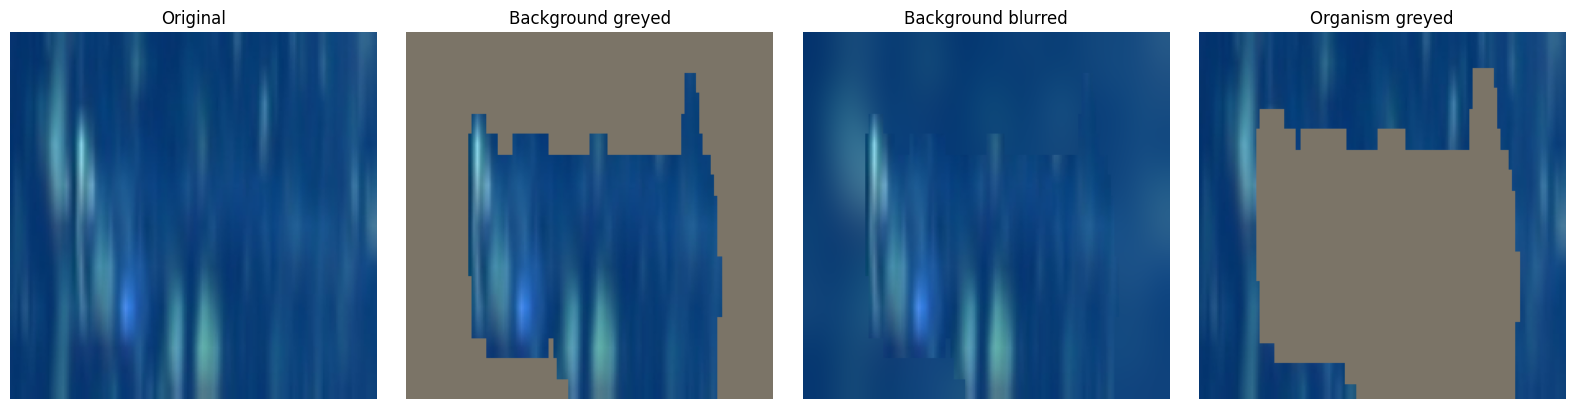

In [ ]:
import matplotlib.pyplot as plt
import torch

idx = 0   # which shallow test crop to show; try 20 or 25 if this one isn't clear
img, label, mask = shallow_test_mask_loader.dataset[idx]
mean = torch.tensor(data.IMAGENET_MEAN).view(1, 3, 1, 1)
std = torch.tensor(data.IMAGENET_STD).view(1, 3, 1, 1)

fig, axes = plt.subplots(1, 4, figsize=(16, 4))
for ax, mode in zip(axes, extensions.MODES):
    x = extensions.apply_intervention(img[None], mask[None], mode)
    ax.imshow((x * std + mean).clamp(0, 1)[0].permute(1, 2, 0).numpy())
    ax.set_title(extensions.MODE_LABELS[mode], fontsize=12)
    ax.axis('off')
plt.tight_layout()
fig.savefig('results/intervention_examples.png', dpi=150, bbox_inches='tight')
plt.show()